# Lab 02 — Nhiệm vụ II.5: Kết hợp Canny với phân đoạn và nhận dạng hình dạng

**Thành viên thực hiện (TV5): NGUYEN DANG THAI** Phụ trách Mục II.5

## Mục tiêu và câu hỏi thực nghiệm

Kết hợp bản đồ biên Canny với xử lý hình thái học (morphology), contours/mask và đặc trưng hình học để tìm vùng và ước lượng hình dạng đối tượng.


In [1]:
from pathlib import Path
import time 
import cv2
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt

In [9]:
plt.rcParams["figure.dpi"] = 120

LAB2_DIR = Path.cwd().resolve()
if LAB2_DIR.name == "notebook":
    LAB2_DIR = LAB2_DIR.parent

INPUT_DIR = LAB2_DIR / "data" / "input"
FIG_DIR = LAB2_DIR / "result" / "figures" / "tv5_segmentation_shapes"
FIG_DIR.mkdir(parents=True, exist_ok=True)


# Hàm đọc ảnh 
def read_bgr(path):
        return cv2.imread(str(path))

#Hàm lưu ảnh 
def save_fig(fig, filename):
        fig.tight_layout()
        fig.savefig(FIG_DIR / filename, dpi=160, bbox_inches="tight")

#Hàm hiển thị ảnh 
def show_gray(ax, img, title):
        ax.imshow(img, cmap="gray", vmin=0, vmax=255)
        ax.set_title(title, fontsize=9)
        ax.axis("off")

---
## Quy trình Canny và morphology

Quy trình : ảnh màu → ảnh xám → Gaussian blur → Canny → closing/dilation → contours → mask. 

Gaussian blur làm giảm nhiễu nhỏ trước khi tính gradient; ngưỡng Canny kiểm soát độ nhạy phát hiện biên. Kernel morphology được giữ nhỏ để hạn chế nhập các vật thể gần nhau.

In [ ]:
SAMPLES = {
    "Hình học rõ nét": "01_hinh_hoc_ro_net.png",
    "Đồng xu": "05_dong_xu_phan_doan.png",
    "Nhiều đối tượng": "08_nhieu_doi_tuong.png",
}

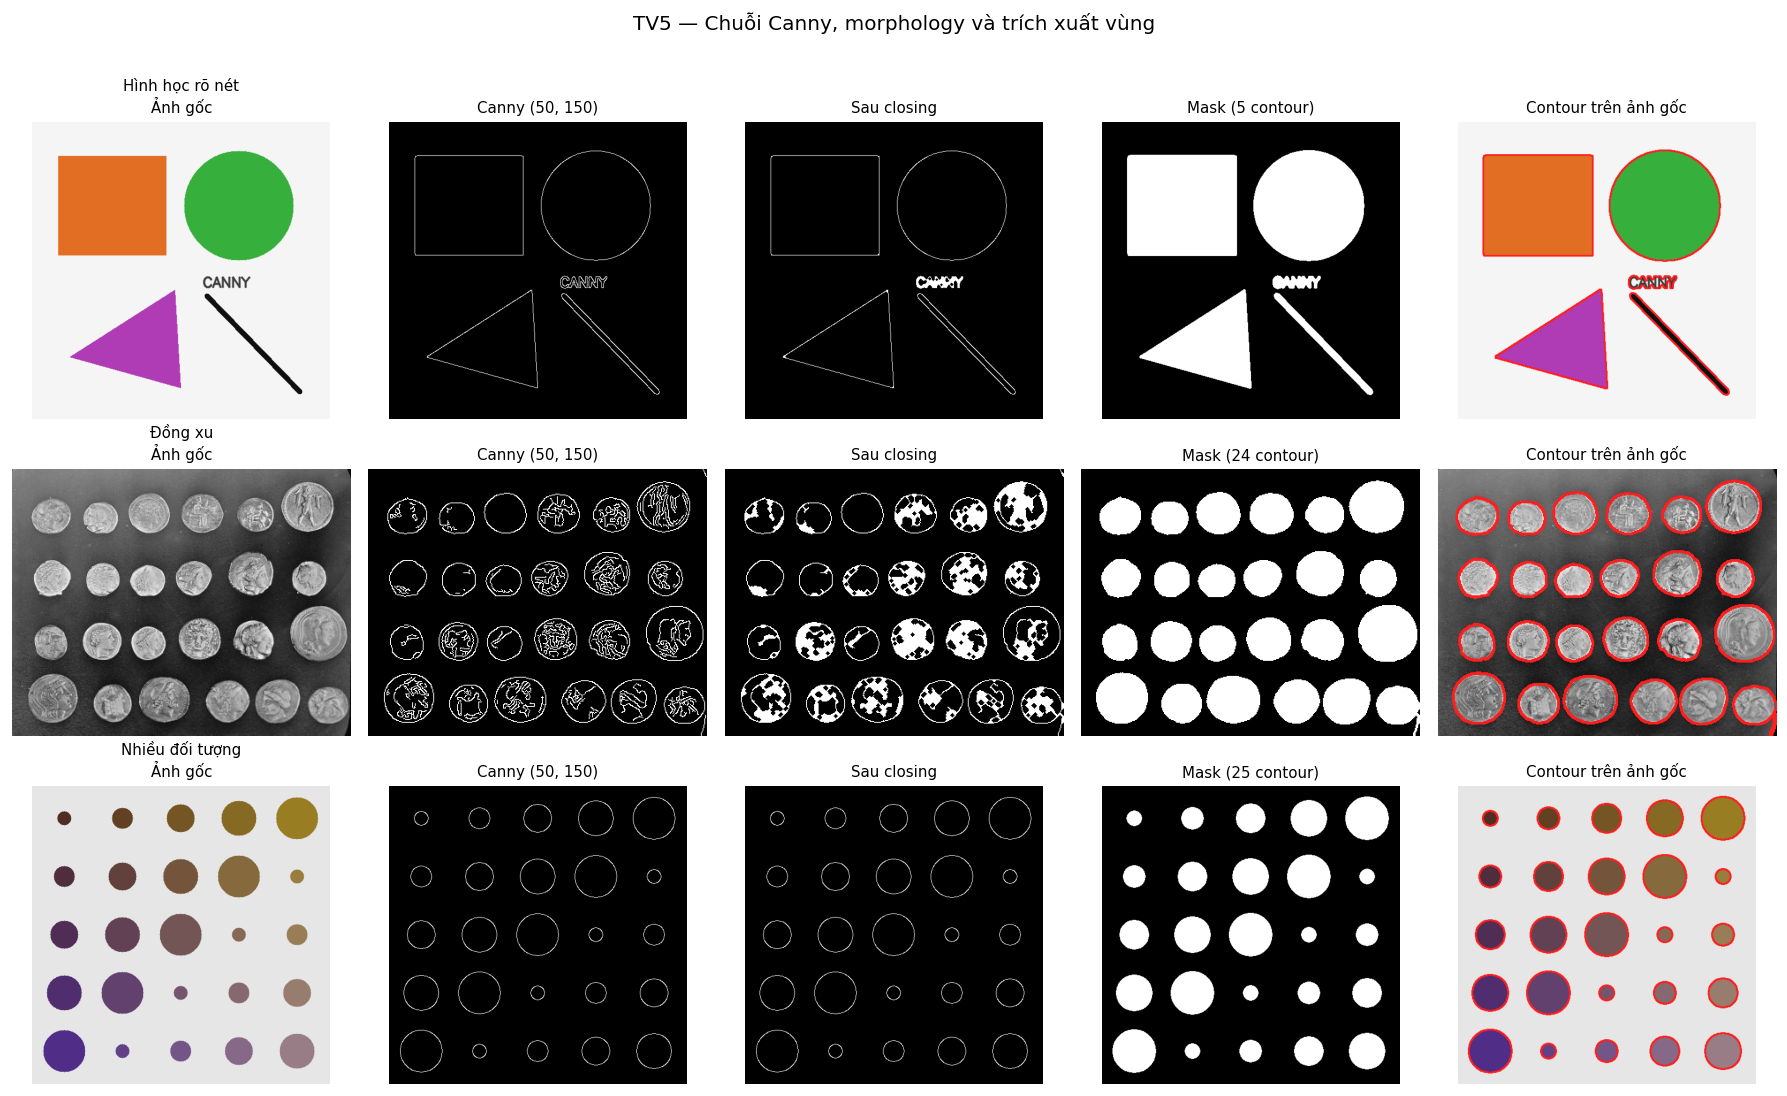

In [11]:
results = {}
for label, filename in SAMPLES.items():
    bgr = read_bgr(INPUT_DIR / filename)
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    blur = cv2.GaussianBlur(gray, (5, 5), 1.0)
    edges = cv2.Canny(blur, 50, 150)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
    closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel, iterations=2)
    dilated = cv2.dilate(closed, kernel, iterations=1)
    contours, _ = cv2.findContours(dilated.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    # Lọc contour quá nhỏ để tránh đếm các đốm nhiễu; ngưỡng chỉ là heuristic.
    h, w = gray.shape
    min_area = max(30, 0.0002 * h * w)
    kept = [c for c in contours if cv2.contourArea(c) >= min_area]
    mask = np.zeros_like(gray)
    cv2.drawContours(mask, kept, -1, 255, thickness=cv2.FILLED)
    overlay = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB).copy()
    cv2.drawContours(overlay, kept, -1, (255, 30, 30), 2)
    results[label] = dict(filename=filename, bgr=bgr, gray=gray, blur=blur,
                          edges=edges, closed=closed, dilated=dilated,
                          contours=kept, mask=mask, overlay=overlay)

fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for row, (label, r) in enumerate(results.items()):
    axes[row, 0].imshow(cv2.cvtColor(r["bgr"], cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title(f"{label}\nẢnh gốc", fontsize=9); axes[row, 0].axis("off")
    show_gray(axes[row, 1], r["edges"], "Canny (50, 150)")
    show_gray(axes[row, 2], r["closed"], "Sau closing")
    show_gray(axes[row, 3], r["mask"], f"Mask ({len(r['contours'])} contour)")
    axes[row, 4].imshow(r["overlay"]); axes[row, 4].set_title("Contour trên ảnh gốc", fontsize=9); axes[row, 4].axis("off")
fig.suptitle("TV5 — Chuỗi Canny, morphology và trích xuất vùng", y=1.01)
save_fig(fig, "01_canny_morphology_contours.png")
plt.show()

**Kết quả:** 

Contour màu đỏ là đường bao tìm được từ bản đồ biên sau morphology. 

Mask tô trắng các contour được giữ lại. Đây là minh họa vùng suy ra từ cạnh, không đảm bảo là phân đoạn ngữ nghĩa chính xác. 

Nếu đường biên bị hở, contour có thể bao nhầm phần lớn nền; nếu dilation quá mạnh, các đối tượng gần nhau có thể nhập thành một vùng.

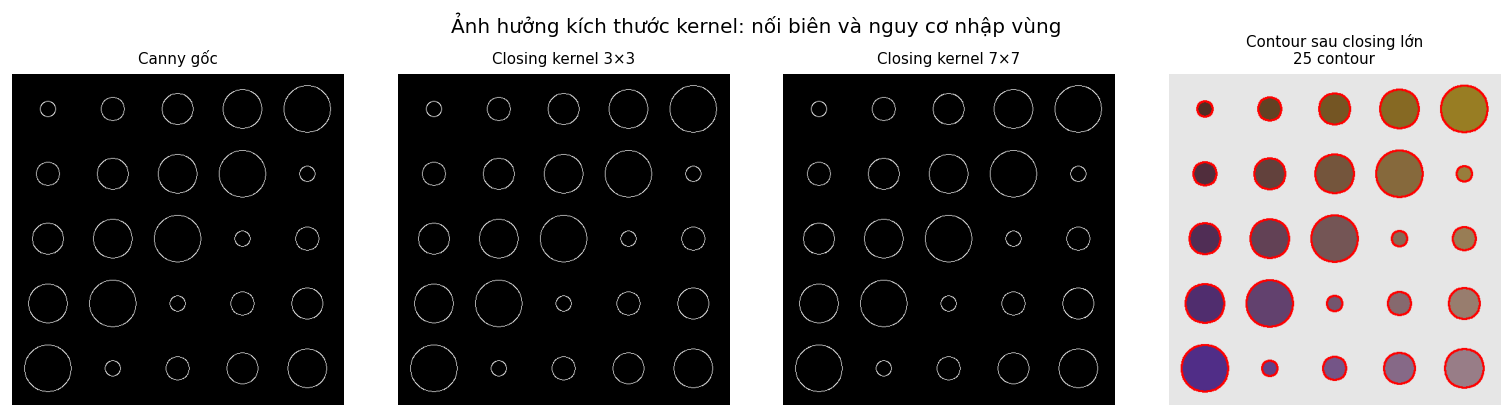

In [12]:
# So sánh kernel nhỏ và lớn trên ảnh nhiều đối tượng.
r = results["Nhiều đối tượng"]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
show_gray(axes[0], r["edges"], "Canny gốc")
for ax, ksize, title in [(axes[1], 3, "Closing kernel 3×3"),
                          (axes[2], 7, "Closing kernel 7×7")]:
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ksize, ksize))
    out = cv2.morphologyEx(r["edges"], cv2.MORPH_CLOSE, kernel, iterations=2)
    show_gray(ax, out, title)
    if ksize == 7:
        big = out
small_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
small = cv2.morphologyEx(r["edges"], cv2.MORPH_CLOSE, small_kernel, iterations=2)
# Vẽ contours của hai thiết lập để thấy ảnh hưởng lên số vùng.
for ax, binary, title in [(axes[3], big, "Contour sau closing lớn")]:
    cnts, _ = cv2.findContours(binary.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    rgb = cv2.cvtColor(r["bgr"], cv2.COLOR_BGR2RGB).copy()
    cv2.drawContours(rgb, [c for c in cnts if cv2.contourArea(c) > 30], -1, (255, 0, 0), 2)
    ax.imshow(rgb); ax.set_title(f"{title}\n{len([c for c in cnts if cv2.contourArea(c)>30])} contour", fontsize=9); ax.axis("off")
fig.suptitle("Ảnh hưởng kích thước kernel: nối biên và nguy cơ nhập vùng")
save_fig(fig, "02_morphology_kernel_comparison.png")
plt.show()

### Nhận xét morphology

- Kernel nhỏ chỉ nối các khe nhỏ, thường bảo toàn khoảng cách giữa các đối tượng tốt hơn.
- Kernel lớn có thể nối nhiều đoạn biên hơn nhưng làm mất ranh giới giữa vật thể gần nhau, khiến contour và mask không còn phản ánh đúng từng đối tượng.
- Số contour không phải chỉ số chất lượng tuyệt đối: một đối tượng có thể tạo nhiều contour nếu biên hở; nhiều đối tượng có thể bị gộp thành một contour.

---
## So sánh Canny-contours với phân ngưỡng Otsu

Otsu là phương pháp phân đoạn dựa trên cường độ xám, tự chọn ngưỡng chia pixel thành hai lớp. Trong khi đó, Canny phát hiện ranh giới cường độ. Vì vậy, hai kết quả thể hiện hai loại thông tin khác nhau: đường biên so với vùng pixel được phân loại.

C:\Users\adu\AppData\Local\Temp\ipykernel_2848\68160640.py:18: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


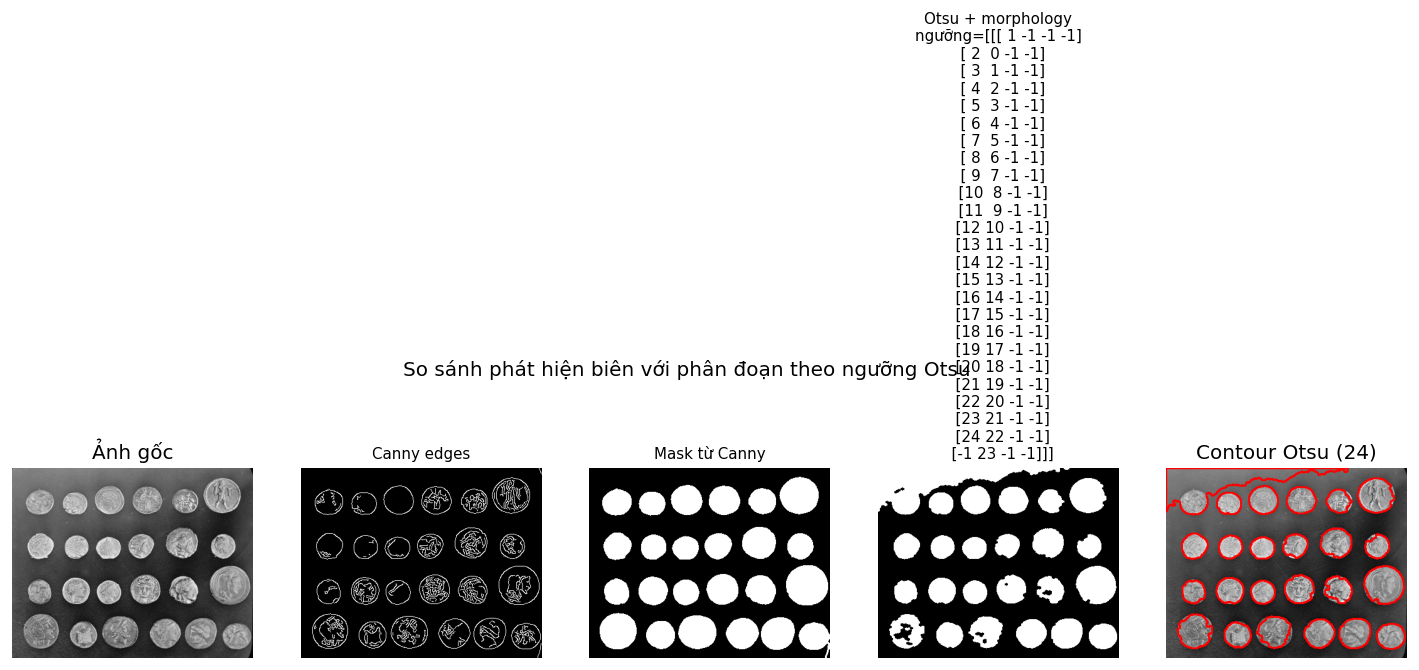

Số contour từ Canny: 24
Số contour từ Otsu: 24


In [13]:
# Chọn ảnh đồng xu để so sánh hai cách tạo vùng.
r = results["Đồng xu"]
gray = r["gray"]
_, otsu = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
# Đảo mask nếu nền trắng chiếm đa số, giúp hiển thị đối tượng tối trên nền sáng dễ hơn.
if np.mean(otsu == 255) > 0.5:
    otsu = cv2.bitwise_not(otsu)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
otsu_clean = cv2.morphologyEx(otsu, cv2.MORPH_OPEN, kernel, iterations=1)
otsu_clean = cv2.morphologyEx(otsu_clean, cv2.MORPH_CLOSE, kernel, iterations=1)
otsu_contours, _ = cv2.findContours(otsu_clean.copy(), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
otsu_contours = [c for c in otsu_contours if cv2.contourArea(c) > 100]
otsu_overlay = cv2.cvtColor(r["bgr"], cv2.COLOR_BGR2RGB).copy()
cv2.drawContours(otsu_overlay, otsu_contours, -1, (255, 0, 0), 2)

fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))
axes[0].imshow(cv2.cvtColor(r["bgr"], cv2.COLOR_BGR2RGB)); axes[0].set_title("Ảnh gốc"); axes[0].axis("off")
show_gray(axes[1], r["edges"], "Canny edges")
show_gray(axes[2], r["mask"], "Mask từ Canny")
show_gray(axes[3], otsu_clean, f"Otsu + morphology\nngưỡng={_}")
axes[4].imshow(otsu_overlay); axes[4].set_title(f"Contour Otsu ({len(otsu_contours)})"); axes[4].axis("off")
fig.suptitle("So sánh phát hiện biên với phân đoạn theo ngưỡng Otsu")
save_fig(fig, "03_canny_vs_otsu.png")
plt.show()
print("Số contour từ Canny:", len(r["contours"]))
print("Số contour từ Otsu:", len(otsu_contours))

---
## Ước lượng số đỉnh bằng `approxPolyDP`

Với mỗi contour, tính chu vi, diện tích và xấp xỉ đa giác. Quy tắc phân loại bên dưới chỉ mang tính minh họa: 3 đỉnh → tam giác, 4 đỉnh → tứ giác, 5 đỉnh → ngũ giác, nhiều hơn → đa giác/nhiều cạnh. Contour không đủ lớn bị loại trước khi xấp xỉ.

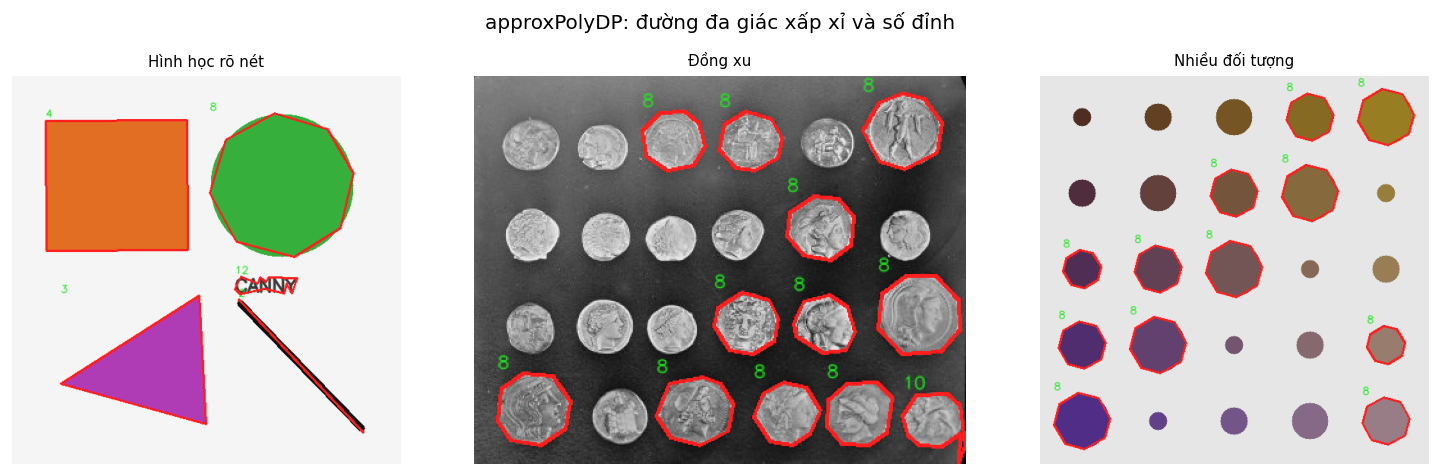

,Ảnh,Diện tích contour (px²),Chu vi (px),Số đỉnh xấp xỉ,Hình dạng ước lượng,Circularity
0,Hình học rõ nét,32507.0,717.3,4,Tứ giác (ước lượng),0.794
1,Hình học rõ nét,28316.0,628.8,8,Đa giác/nhiều cạnh,0.900
2,Hình học rõ nét,16478.0,619.4,3,Tam giác (ước lượng),0.540
3,Hình học rõ nét,2639.0,496.7,2,Chưa xác định,0.134
4,Hình học rõ nét,1337.5,277.7,12,Đa giác/nhiều cạnh,0.218
5,Đồng xu,3354.5,216.4,8,Đa giác/nhiều cạnh,0.900
6,Đồng xu,2792.5,199.2,8,Đa giác/nhiều cạnh,0.884
7,Đồng xu,2641.5,192.8,8,Đa giác/nhiều cạnh,0.893
8,Đồng xu,2529.0,190.5,8,Đa giác/nhiều cạnh,0.876
9,Đồng xu,2170.5,174.6,8,Đa giác/nhiều cạnh,0.895


In [14]:
def shape_name(vertices):
    if vertices == 3:
        return "Tam giác (ước lượng)"
    if vertices == 4:
        return "Tứ giác (ước lượng)"
    if vertices == 5:
        return "Ngũ giác (ước lượng)"
    if vertices == 6:
        return "Lục giác (ước lượng)"
    if vertices > 6:
        return "Đa giác/nhiều cạnh"
    return "Chưa xác định"

shape_rows = []
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, label in zip(axes, ["Hình học rõ nét", "Đồng xu", "Nhiều đối tượng"]):
    r = results[label]
    canvas = cv2.cvtColor(r["bgr"], cv2.COLOR_BGR2RGB).copy()
    # Chỉ lấy các contour có diện tích tương đối đáng kể.
    candidates = sorted(r["contours"], key=cv2.contourArea, reverse=True)[:12]
    for idx, cnt in enumerate(candidates):
        area = cv2.contourArea(cnt)
        perimeter = cv2.arcLength(cnt, True)
        if perimeter <= 0 or area < 80:
            continue
        approx = cv2.approxPolyDP(cnt, 0.02 * perimeter, True)
        vertices = len(approx)
        circularity = (4 * np.pi * area / (perimeter ** 2)) if perimeter else 0
        cv2.drawContours(canvas, [approx], -1, (255, 30, 30), 2)
        x, y, w, h = cv2.boundingRect(approx)
        cv2.putText(canvas, str(vertices), (x, max(12, y-4)),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.45, (30, 230, 30), 1, cv2.LINE_AA)
        shape_rows.append({
            "Ảnh": label, "Diện tích contour (px²)": round(area, 1),
            "Chu vi (px)": round(perimeter, 1), "Số đỉnh xấp xỉ": vertices,
            "Hình dạng ước lượng": shape_name(vertices),
            "Circularity": round(float(circularity), 3)
        })
    ax.imshow(canvas); ax.set_title(label, fontsize=9); ax.axis("off")
fig.suptitle("approxPolyDP: đường đa giác xấp xỉ và số đỉnh")
save_fig(fig, "04_approx_poly_dp_shapes.png")
plt.show()

shape_df = pd.DataFrame(shape_rows)
display(shape_df.head(20))

# Phân tích Hình học Đồng xu trong Xử lý Ảnh

## 1. Độ tròn (Circularity)
Circularity là một số đo đặc trưng hình học dùng để đánh giá mức độ "tròn" của một đối tượng dựa trên diện tích và chu vi của nó.

* **Công thức toán học:**
  $$\text{Circularity} = \frac{4 \pi \cdot A}{P^2}$$
  * Trong đó:
    * $A$ ($Area$): Diện tích của contour.
    * $P$ ($Perimeter$): Chu vi của contour.

* **Đặc điểm thực tế:**
  * **Hình tròn lý tưởng:** Có giá trị bằng **1**.
  * **Ảnh thực tế:** Giá trị này thường dao động và phụ thuộc lớn vào **độ kín** (tính liên tục) và **độ mịn** của đường contour sau bước phân đoạn ảnh.

---

## 2. Phương pháp biến đổi Hough Circle (Hough Circle Transform)
Hough Circle là một thuật toán dò tìm nâng cao được sử dụng song song hoặc bổ sung cho phương pháp dựa trên contour.

* **Cơ chế hoạt động:** Phép dò này dựa trên cấu trúc hình học hình tròn tổng quát thông qua việc bỏ phiếu (voting) trong không gian tham số.
* **Ưu điểm:** Hoạt động độc lập và **không phụ thuộc hoàn toàn** vào các đường contour đã được tạo ra ở các bước xử lý trước đó. Nhờ vậy, thuật toán vẫn tìm được đồng xu ngay cả khi biên dạng bị đứt gãy hoặc nhiễu.
"

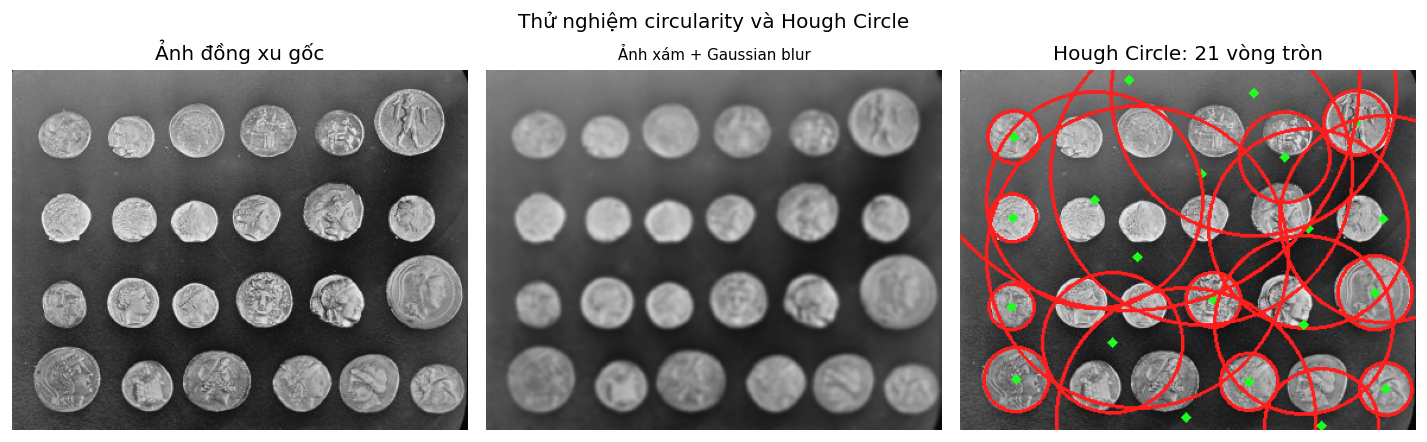

Circularity các contour đủ lớn (tối đa 10): [0.503, 0.901, 0.893, 0.895, 0.876, 0.893, 0.892, 0.872, 0.888, 0.852]
Số vòng tròn Hough phát hiện: 21


In [15]:
r = results["Đồng xu"]
gray = r["gray"]
blur = cv2.GaussianBlur(gray, (9, 9), 1.5)
circles = cv2.HoughCircles(
    blur, cv2.HOUGH_GRADIENT, dp=1.2, minDist=max(20, gray.shape[0] // 5),
    param1=100, param2=32, minRadius=10, maxRadius=0
)
circle_canvas = cv2.cvtColor(r["bgr"], cv2.COLOR_BGR2RGB).copy()
hough_count = 0
if circles is not None:
    circles = np.round(circles[0]).astype(int)
    hough_count = len(circles)
    for x, y, radius in circles:
        cv2.circle(circle_canvas, (x, y), radius, (255, 30, 30), 2)
        cv2.circle(circle_canvas, (x, y), 2, (30, 255, 30), 3)

circularities = []
for cnt in r["contours"]:
    area = cv2.contourArea(cnt)
    perimeter = cv2.arcLength(cnt, True)
    if area > 50 and perimeter > 0:
        circularities.append(4 * np.pi * area / (perimeter ** 2))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].imshow(cv2.cvtColor(r["bgr"], cv2.COLOR_BGR2RGB)); axes[0].set_title("Ảnh đồng xu gốc"); axes[0].axis("off")
show_gray(axes[1], blur, "Ảnh xám + Gaussian blur")
axes[2].imshow(circle_canvas); axes[2].set_title(f"Hough Circle: {hough_count} vòng tròn"); axes[2].axis("off")
fig.suptitle("Thử nghiệm circularity và Hough Circle")
save_fig(fig, "05_circularity_hough_circle.png")
plt.show()
print("Circularity các contour đủ lớn (tối đa 10):", [round(float(x), 3) for x in circularities[:10]])
print("Số vòng tròn Hough phát hiện:", hough_count)

## Kết luận

- **Canny hỗ trợ tốt** khi ranh giới có tương phản đủ rõ và mục tiêu là định vị cạnh, đo đường bao hoặc trích xuất đặc trưng hình học.
- **Morphology** giúp nối khe hở nhỏ và làm contour liền hơn; kernel phải được chọn theo tỷ lệ kích thước đối tượng và khoảng cách giữa các vật thể.
- **Contours + mask** tạo vùng minh họa từ biên, nhưng chất lượng phụ thuộc việc biên có khép kín hay không.
- **Otsu** có thể tạo vùng tốt khi đối tượng và nền khác biệt về cường độ; Canny lại thể hiện đường ranh giới, không trực tiếp phân loại pixel thành vùng đối tượng/nền.
- **approxPolyDP, circularity và Hough** là các bộ ước lượng hình dạng, không phải nhận dạng chắc chắn. Cần điều chỉnh tham số và kiểm tra kết quả trên ảnh gốc.
- Khi gặp biên hở, vật thể chồng lấp, nền phức tạp hoặc hình tròn không hoàn hảo, nên kết hợp phương pháp theo vùng (Otsu/adaptive threshold, watershed) hoặc thêm thông tin màu sắc/kết cấu.